# EDA — NASA Technical Reports Server (NTRS)

Análise exploratória da fonte NTRS para o desafio *Create Health Monitoring Software for Astronauts on Space Missions* (NASA Space Apps 2026).

**Objetivos**
1. Avaliar cobertura, qualidade e utilidade do NTRS para o projeto.
2. Identificar documentos com faixas e valores de referência dos indicadores de saúde (limiares).

**Entrada:** `ntrs_saude.parquet`, gerado pelo notebook de coleta.

**Recorte da coleta:** divisão *Life Sciences* do esquema de categorias do NASA STI (exceto Exobiology) mais *Space Radiation*. 43.917 documentos na API, 42.562 coletados (96,9%), 41.866 únicos. Os 1.355 não coletados são documentos sem data de publicação em Life Sciences e Man/System, perdidos no fatiamento por data exigido pelo limite de paginação da API (10.000 registros por consulta).

## 1. Configuração

In [ ]:
import json
import os
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

COR = "#3B6FB6"  # cor única para gráficos de uma série
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
})

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/space-apps-2026/ntrs"
except ImportError:
    DATA_DIR = "data"  # execução local

PARQUET_PATH = os.path.join(DATA_DIR, "ntrs_saude.parquet")
SAIDA_DIR = os.path.join(DATA_DIR, "eda")
os.makedirs(SAIDA_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Carregamento

In [ ]:
df = pd.read_parquet(PARQUET_PATH)

# colunas aninhadas foram salvas como texto JSON
def decodificar(v):
    if isinstance(v, str) and v[:1] in "[{":
        try:
            return json.loads(v)
        except json.JSONDecodeError:
            return v
    return v

for col in df.columns:
    amostra = df[col].dropna().head(50)
    if len(amostra) and amostra.apply(lambda v: isinstance(v, str) and v[:1] in "[{").all():
        df[col] = df[col].apply(decodificar)

print(df.shape)

(41866, 36)


## 3. Qualidade: preenchimento dos campos

In [ ]:
def tipo_real(serie):
    nao_nulos = serie.dropna()
    return type(nao_nulos.iloc[0]).__name__ if len(nao_nulos) else "vazio"

def preenchido(v):
    if v is None or (isinstance(v, float) and pd.isna(v)):
        return False
    if isinstance(v, (list, dict, str)) and len(v) == 0:
        return False
    return True

schema = pd.DataFrame({
    "tipo": {c: tipo_real(df[c]) for c in df.columns},
    "pct_preenchido": {c: round(100 * df[c].apply(preenchido).mean(), 1) for c in df.columns},
}).sort_values("pct_preenchido", ascending=False)
schema

,tipo,pct_preenchido
id,int64,100.0
_meta,dict,100.0
copyright,dict,100.0
subjectCategories,list,100.0
exportControl,dict,100.0
distributionDate,str,100.0
stiType,str,100.0
title,str,100.0
distribution,str,100.0
technicalReviewType,str,100.0


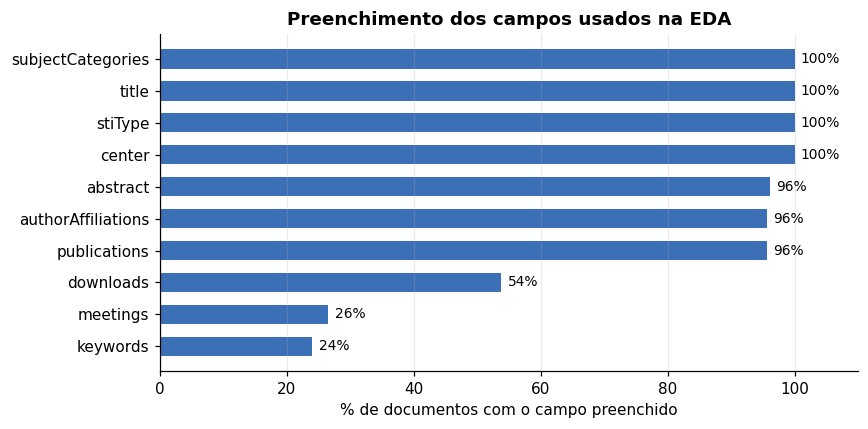

In [ ]:
CAMPOS_EDA = ["title", "subjectCategories", "stiType", "center", "abstract",
              "publications", "authorAffiliations", "downloads", "meetings", "keywords"]

s = schema.loc[CAMPOS_EDA, "pct_preenchido"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(s.index, s.values, color=COR, height=0.6)
for i, v in enumerate(s.values):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% de documentos com o campo preenchido")
ax.set_title("Preenchimento dos campos usados na EDA")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Leitura**
- `abstract` presente em 96% dos documentos: viabiliza NLP sobre o corpus quase inteiro.
- `downloads` em 54%: só metade tem arquivo, e é nessa metade que valores numéricos completos podem ser encontrados.
- `keywords` em 24%: insuficiente para mapear temas. Os temas são extraídos dos resumos (seção 10).
- Campos como `copyright`, `exportControl`, `legacyMeta` e `cui` são metadado administrativo e ficam fora da análise.

## 4. DataFrame limpo

In [ ]:
BASE_NTRS = "https://ntrs.nasa.gov"
ANO_MINIMO = 1945  # anterior a qualquer pesquisa de medicina espacial

def ano_publicacao(pubs):
    if not isinstance(pubs, list):
        return None
    datas = [p.get("publicationDate") for p in pubs if isinstance(p, dict) and p.get("publicationDate")]
    if not datas:
        return None
    ano = int(min(datas)[:4])
    return ano if ano >= ANO_MINIMO else None

def link_fulltext(downloads):
    if not isinstance(downloads, list):
        return None
    for d in downloads:
        link = d.get("links", {}).get("fulltext") if isinstance(d, dict) else None
        if link:
            return BASE_NTRS + link
    return None

def limpar_lista(v):
    return [s.strip() for s in v if isinstance(s, str) and s.strip()] if isinstance(v, list) else []

dados = pd.DataFrame({
    "id": df["id"],
    "titulo": df["title"],
    "resumo": df["abstract"].fillna(""),
    "ano": df["publications"].apply(ano_publicacao).astype("Int64"),
    "tipo": df["stiType"],
    "centro": df["center"].apply(lambda c: c.get("code") if isinstance(c, dict) else None),
    # .title() unifica grafias como "And" e "and"
    "categorias": df["subjectCategories"].apply(lambda v: sorted({s.title() for s in limpar_lista(v)})),
    "palavras_chave": df["keywords"].apply(lambda v: [s.lower() for s in limpar_lista(v)]),
    "n_autores": df["authorAffiliations"].apply(lambda v: len(v) if isinstance(v, list) else 0),
    "link_texto": df["downloads"].apply(link_fulltext),
})
dados["n_palavras_resumo"] = dados["resumo"].str.split().str.len()
dados["tem_texto"] = dados["link_texto"].notna()
dados["decada"] = (dados["ano"] // 10 * 10).astype("Int64")

print(dados.shape)
print("documentos sem ano válido:", dados["ano"].isna().sum())
dados.head(3)

(41866, 13)
documentos sem ano válido: 1884


,id,titulo,resumo,ano,tipo,centro,categorias,palavras_chave,n_autores,link_texto,n_palavras_resumo,tem_texto,decada
0,19640003002,Results of the Project Mercury Ballistic-and Orbital Chimpanzee Flights,"This publication presents a full account of the flights of the Project Mercury chimpanzees, from...",1963,SPECIAL_PUBLICATION,JSC,"[Aerospace Medicine, Life Sciences (General)]","[ballistic trajectory, orbit, chimpanzee]",2,https://ntrs.nasa.gov/api/citations/19640003002/downloads/19640003002-final.pdf.txt,74,True,1960
1,19650008965,Conference on Nutrition in Space and Related Waste Problems,"As part of a continuing process man constantly seeks new habitats. In the late 1950's, he ventur...",1964,SPECIAL_PUBLICATION,HQ,[Aerospace Medicine],"[nutrition, conference, space environment]",1,https://ntrs.nasa.gov/api/citations/19650008965/downloads/19650008965.txt,289,True,1960
2,19650008974,Nutrition and Stresses of Short Term Space Flight,The nutritional requirements for short-term space flights which are most likely to be affected b...,1964,CONFERENCE_PAPER,CDMS,[Aerospace Medicine],"[nutrition, biological stress, manned space flight]",1,None,67,False,1960


Decisões de limpeza:
- **Ano:** data de publicação mais antiga do registro. Anos anteriores a 1945 são tratados como ausentes (há um registro com ano 992).
- **Categorias:** capitalização padronizada, porque a fonte grava a mesma categoria com grafias diferentes ("And" e "and").
- **Autores:** só a contagem. Os nomes não são padronizados (ex.: "Cucinotta, F. A." e "Cucinotta, Francis A.").

## 5. Distribuição no tempo

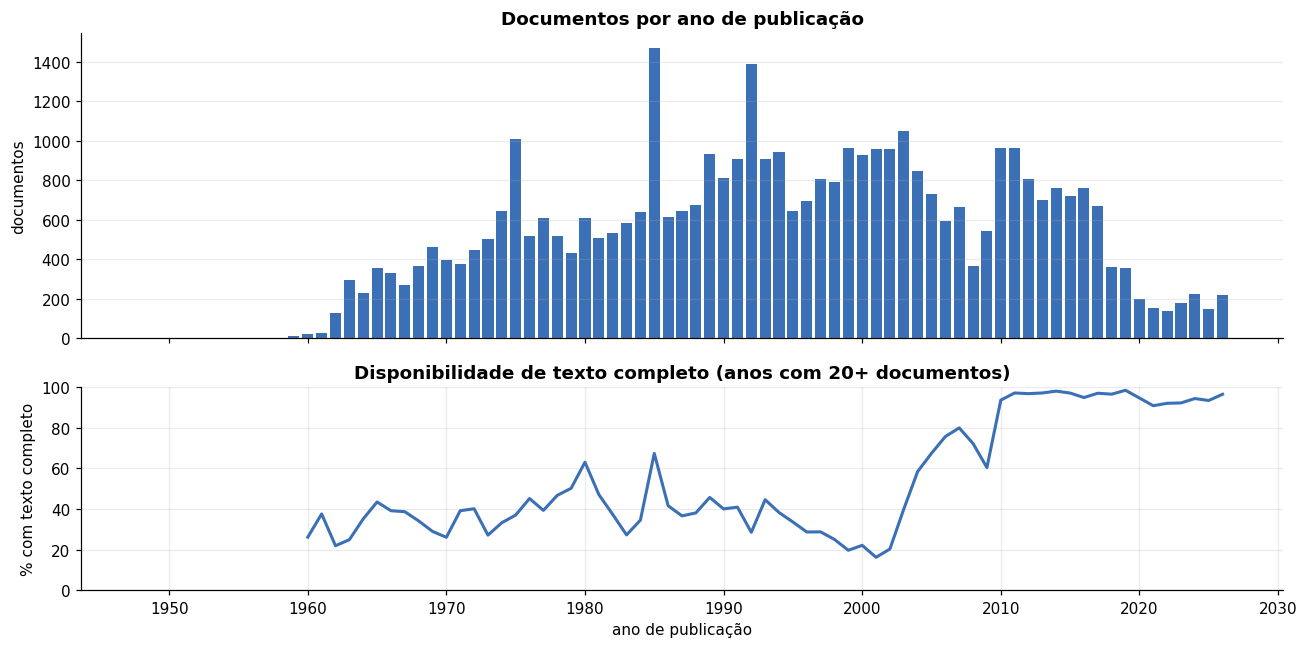

mediana do ano: 1994.0


,documentos,pct_com_texto
ano,,
2015,722,97.0
2016,761,94.7
2017,668,96.9
2018,361,96.4
2019,355,98.3
2020,201,94.5
2021,151,90.7
2022,136,91.9
2023,177,92.1


In [ ]:
por_ano = dados.groupby("ano").agg(documentos=("id", "size"), pct_com_texto=("tem_texto", "mean"))
por_ano["pct_com_texto"] *= 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
ax1.bar(por_ano.index, por_ano["documentos"], color=COR, width=0.8)
ax1.set_ylabel("documentos")
ax1.set_title("Documentos por ano de publicação")
ax1.grid(axis="x", visible=False)

confiavel = por_ano[por_ano["documentos"] >= 20]  # % instável em anos com poucos documentos
ax2.plot(confiavel.index, confiavel["pct_com_texto"], color=COR, linewidth=2)
ax2.set_ylim(0, 100)
ax2.set_ylabel("% com texto completo")
ax2.set_xlabel("ano de publicação")
ax2.set_title("Disponibilidade de texto completo (anos com 20+ documentos)")
plt.tight_layout()
plt.show()

print("mediana do ano:", dados["ano"].median())
por_ano.loc[por_ano.index >= 2015].round(1)

**Leitura**
- Metade do corpus foi publicada antes de meados dos anos 1990.
- A disponibilidade de texto completo salta para mais de 90% por volta de 2010 e se mantém. Antes disso oscila entre 20% e 60%, o que indica mudança na forma de submissão à NASA, não no conteúdo.
- O volume anual cai depois de 2017. Pode refletir menor produção, atraso de indexação ou ambos.
- Picos isolados (1975, 1985, 1992) são investigados por tipo de documento na seção 6.

## 6. Tipo de documento

In [ ]:
por_tipo = dados.groupby("tipo").agg(
    documentos=("id", "size"),
    pct_com_texto=("tem_texto", "mean"),
    mediana_palavras_resumo=("n_palavras_resumo", "median"),
    mediana_ano=("ano", "median"),
).sort_values("documentos", ascending=False)
por_tipo["pct_corpus"] = 100 * por_tipo["documentos"] / len(dados)
por_tipo["pct_com_texto"] *= 100
por_tipo.round(1)

,documentos,pct_com_texto,mediana_palavras_resumo,mediana_ano,pct_corpus
tipo,,,,,
REPRINT,12248,5.3,140.0,1992.0,29.3
CONFERENCE_PAPER,8570,58.5,122.0,1989.0,20.5
OTHER,7129,83.3,163.0,2005.0,17.0
PRESENTATION,3256,97.1,31.0,2016.0,7.8
ABSTRACT,3123,45.4,244.0,2009.0,7.5
CONTRACTOR_REPORT,2578,98.4,91.0,1979.0,6.2
TECHNICAL_MEMORANDUM,1251,99.1,100.0,1983.0,3.0
PREPRINT,997,87.4,148.0,2001.0,2.4
CONFERENCE_PROCEEDINGS,881,15.7,97.0,1979.0,2.1


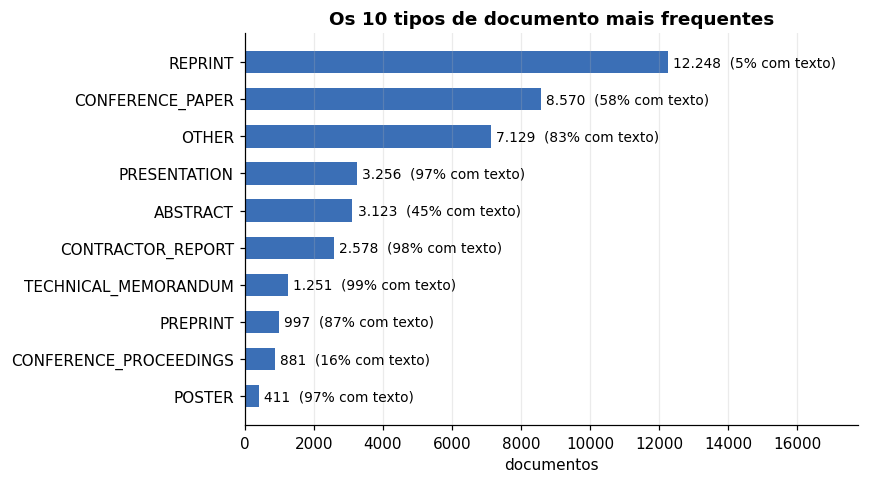

In [ ]:
top = por_tipo.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top["documentos"], color=COR, height=0.6)
for i, (n, p) in enumerate(zip(top["documentos"], top["pct_com_texto"])):
    ax.text(n + 150, i, f"{n:,}  ({p:.0f}% com texto)".replace(",", "."), va="center", fontsize=9)
ax.set_xlim(0, top["documentos"].max() * 1.45)
ax.set_xlabel("documentos")
ax.set_title("Os 10 tipos de documento mais frequentes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
# o que compõe os anos de pico?
for ano in [1975, 1985, 1992]:
    sub = dados[dados["ano"] == ano]
    print(ano, len(sub), "documentos:", sub["tipo"].value_counts().head(3).to_dict())

1975 1007 documentos: {'REPRINT': 237, 'CONTRACTOR_REPORT': 220, 'CONFERENCE_PAPER': 209}
1985 1472 documentos: {'CONFERENCE_PAPER': 1015, 'REPRINT': 274, 'CONTRACTOR_REPORT': 76}
1992 1388 documentos: {'REPRINT': 674, 'CONFERENCE_PAPER': 445, 'OTHER': 116}


**Leitura**
- REPRINT é o tipo mais comum (29% do corpus), mas só 5% tem texto completo. São reimpressões de artigos de periódicos, cujo texto pertence às editoras.
- Os tipos com texto quase sempre disponível são CONTRACTOR_REPORT, TECHNICAL_MEMORANDUM, TECHNICAL_PUBLICATION e SPECIAL_PUBLICATION: relatórios da própria NASA, os mais prováveis de trazer valores e protocolos completos.
- PRESENTATION tem resumo mediano de 31 palavras. Não serve para NLP nem para limiares.
- O pico de 1985 é dominado por CONFERENCE_PAPER (mais de mil), indicando a carga de anais de congresso inteiros. Os picos de 1975 e 1992 misturam tipos.

## 7. Categorias temáticas

categorias distintas: 76


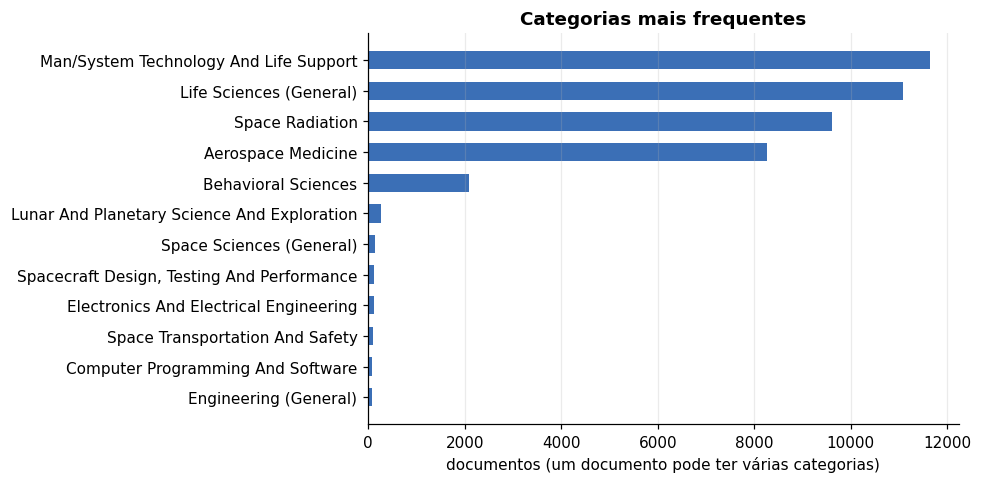

In [ ]:
cats = dados.explode("categorias")["categorias"].value_counts()
print("categorias distintas:", len(cats))

top = cats.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.values, color=COR, height=0.6)
ax.set_xlabel("documentos (um documento pode ter várias categorias)")
ax.set_title("Categorias mais frequentes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
n_cats = dados["categorias"].str.len()
print("documentos com mais de uma categoria:", (n_cats > 1).sum(), f"({100 * (n_cats > 1).mean():.1f}%)")

COLETADAS = ["Aerospace Medicine", "Behavioral Sciences", "Life Sciences (General)",
             "Man/System Technology And Life Support", "Space Radiation"]
coocorrencia = pd.DataFrame(0, index=COLETADAS, columns=COLETADAS)
for lista in dados["categorias"]:
    presentes = [c for c in lista if c in COLETADAS]
    for a in presentes:
        for b in presentes:
            coocorrencia.loc[a, b] += 1
coocorrencia

documentos com mais de uma categoria: 2562 (6.1%)


,Aerospace Medicine,Behavioral Sciences,Life Sciences (General),Man/System Technology And Life Support,Space Radiation
Aerospace Medicine,8257,62,239,214,92
Behavioral Sciences,62,2079,18,33,2
Life Sciences (General),239,18,11091,128,49
Man/System Technology And Life Support,214,33,128,11650,13
Space Radiation,92,2,49,13,9602


As 5 categorias coletadas quase não se sobrepõem. Os documentos também recebem categorias de fora do recorte (planetária, engenharia, software), mas em volume pequeno.

## 8. Centros de origem

In [ ]:
centros = dados["centro"].value_counts()
centros.to_frame("documentos").assign(pct=lambda t: (100 * t["documentos"] / len(dados)).round(1))

,documentos,pct
centro,,
CDMS,22335,53.3
JSC,7188,17.2
ARC,3055,7.3
HQ,2098,5.0
JPL,1622,3.9
MSFC,1361,3.3
GSFC,1357,3.2
KSC,1018,2.4
LaRC,849,2.0


`CDMS` responde por mais da metade dos registros. Não é um centro de pesquisa como JSC (Johnson) ou ARC (Ames), e sim um código de origem de registros, provavelmente de cargas legadas. O código numérico `2230` também não corresponde a um centro. Ambos são problemas de qualidade a registrar. Entre os centros de pesquisa, JSC, sede do programa de saúde de astronautas, domina.

## 9. Resumos

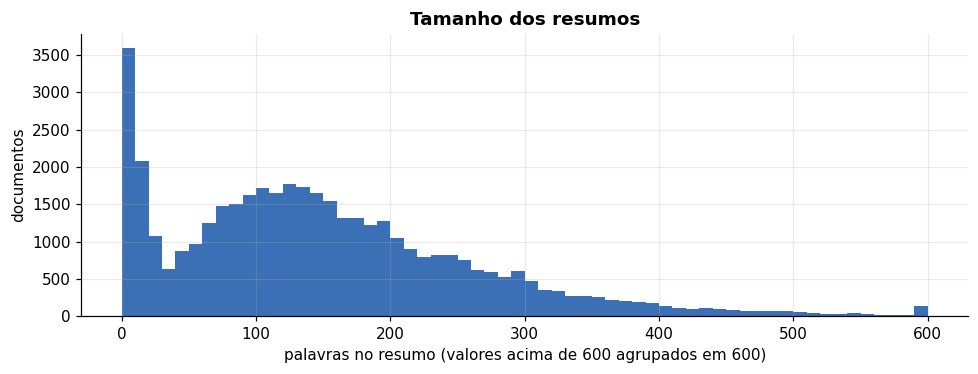

count    41866.0
mean       150.0
std        113.0
min          0.0
25%         69.0
50%        134.0
75%        210.0
max       1246.0
Name: n_palavras_resumo, dtype: float64
resumos com menos de 20 palavras: 5673


In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(dados["n_palavras_resumo"].clip(upper=600), bins=60, color=COR)
ax.set_xlabel("palavras no resumo (valores acima de 600 agrupados em 600)")
ax.set_ylabel("documentos")
ax.set_title("Tamanho dos resumos")
plt.tight_layout()
plt.show()

print(dados["n_palavras_resumo"].describe().round(0))
print("resumos com menos de 20 palavras:", (dados["n_palavras_resumo"] < 20).sum())

## 10. Cobertura dos indicadores do desafio

O statement cita como exemplos pressão arterial, frequência cardíaca, glicemia, temperatura corporal, horas de sono e humor. Os riscos ósseo, muscular e de radiação vêm dos cinco perigos do voo espacial. A busca é por expressões regulares nos títulos e resumos.

In [ ]:
INDICADORES = {
    "pressão arterial": r"blood pressure|hypertensi|hypotensi|orthostatic|mm ?hg",
    "frequência cardíaca": r"heart rate|\bbpm\b|beats/min|tachycard|bradycard|arrhythm",
    "glicemia": r"glucose|insulin|mg/dl",
    "temperatura corporal": r"body temperature|core temperature|thermoregulat",
    "sono": r"\bsleep|circadian|insomnia",
    "humor e comportamento": r"\bmood|depressi|anxiety|psycholog|behavioral health|isolation and confinement",
    "osso": r"\bbone|osteopor|osteopen|bone mineral density",
    "músculo": r"\bmuscle|atrophy|sarcopen",
    "radiação": r"radiation|\bdosimetr|sievert|\bmsv\b",
}

texto_busca = (dados["titulo"].fillna("") + " " + dados["resumo"]).str.lower()
for nome, padrao in INDICADORES.items():
    dados[f"ind_{nome}"] = texto_busca.str.contains(padrao, regex=True)

cols_ind = [f"ind_{n}" for n in INDICADORES]
cobertura = pd.DataFrame({
    "documentos": dados[cols_ind].sum().values,
    "desde_2000": dados.loc[dados["ano"] >= 2000, cols_ind].sum().values,
    "desde_2000_com_texto": dados.loc[(dados["ano"] >= 2000) & dados["tem_texto"], cols_ind].sum().values,
}, index=list(INDICADORES)).sort_values("documentos", ascending=False)
cobertura

,documentos,desde_2000,desde_2000_com_texto
radiação,4813,2127,1497
músculo,1738,641,316
osso,1470,676,467
pressão arterial,1171,471,223
humor e comportamento,909,343,257
frequência cardíaca,829,308,143
sono,758,355,221
glicemia,388,120,40
temperatura corporal,285,72,35


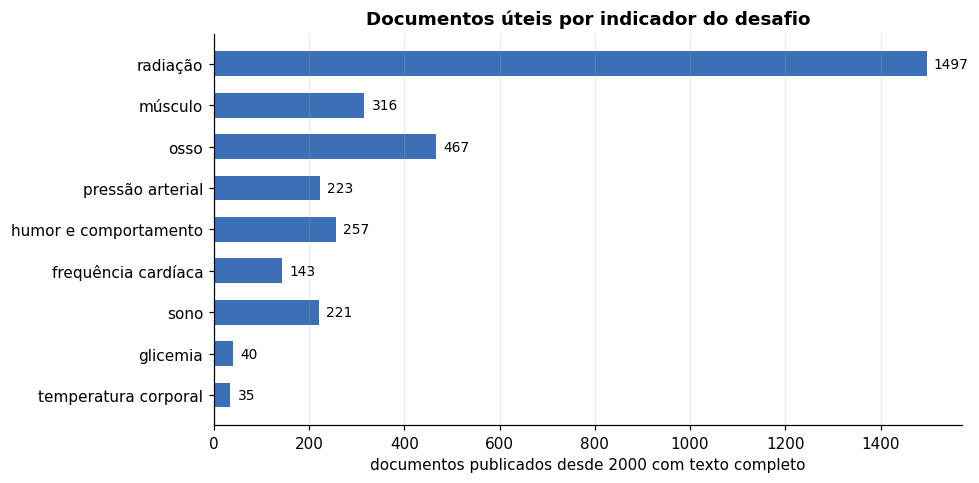

documentos sem nenhum indicador: 31516 (75%)
núcleo útil (algum indicador, desde 2000, com texto completo): 2629


In [ ]:
c = cobertura.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(c.index, c["desde_2000_com_texto"], color=COR, height=0.6)
for i, v in enumerate(c["desde_2000_com_texto"]):
    ax.text(v + 15, i, str(v), va="center", fontsize=9)
ax.set_xlabel("documentos publicados desde 2000 com texto completo")
ax.set_title("Documentos úteis por indicador do desafio")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tem_ind = dados[cols_ind].any(axis=1)
print("documentos sem nenhum indicador:", (~tem_ind).sum(), f"({100 * (~tem_ind).mean():.0f}%)")
nucleo = tem_ind & (dados["ano"] >= 2000) & dados["tem_texto"]
print("núcleo útil (algum indicador, desde 2000, com texto completo):", nucleo.sum())

**Leitura**
- Cerca de 75% dos documentos não mencionam nenhum dos indicadores. O recorte por categoria é amplo, e o núcleo útil ao desafio é bem menor.
- Radiação domina, efeito direto da categoria Space Radiation.
- Temperatura corporal e glicemia, citados no statement, têm só algumas dezenas de documentos recentes com texto completo. O NTRS sustenta pouco os limiares desses dois indicadores.

## 11. Temas dos resumos (NLP)

Modelagem de tópicos com TF-IDF e NMF sobre os resumos com pelo menos 30 palavras. O objetivo é ver quais assuntos o corpus realmente cobre, sem depender das categorias ou das palavras-chave dos autores.

In [ ]:
corpus = dados[dados["n_palavras_resumo"] >= 30].copy()

STOP_EXTRA = ["nasa", "study", "studies", "results", "data", "use", "used", "using", "paper",
              "presented", "present", "research", "new", "based", "include", "including",
              "also", "may", "results", "provide", "discussed", "described", "report"]

vetorizador = TfidfVectorizer(
    stop_words=list(TfidfVectorizer(stop_words="english").get_stop_words()) + STOP_EXTRA,
    max_df=0.4, min_df=10, max_features=20000, ngram_range=(1, 2),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z-]{2,}\b",
)
X = vetorizador.fit_transform(corpus["resumo"])
print("documentos:", X.shape[0], "| termos:", X.shape[1])

documentos: 35112 | termos: 20000


In [ ]:
N_TOPICOS = 15
nmf = NMF(n_components=N_TOPICOS, random_state=42, init="nndsvda", max_iter=400)
W = nmf.fit_transform(X)
termos = np.array(vetorizador.get_feature_names_out())

topicos = pd.DataFrame({
    "termos_principais": [", ".join(termos[np.argsort(comp)[::-1][:10]]) for comp in nmf.components_],
})
corpus["topico"] = W.argmax(axis=1)
topicos["documentos"] = corpus["topico"].value_counts().reindex(range(N_TOPICOS), fill_value=0)
topicos.sort_values("documentos", ascending=False)

,termos_principais,documentos
12,"control, model, performance, task, human, software, pilot, systems, information, design",7459
5,"cells, cell, growth, protein, expression, culture, gene, microgravity, tissue, gravity",4557
2,"exercise, blood, pressure, muscle, rest, body, subjects, changes, volume, bed rest",3780
4,"water, life support, life, support, carbon, oxygen, systems, plant, waste, food",3349
14,"suit, eva, design, test, lunar, testing, extravehicular, space suit, plss, thermal",1986
1,"energy, mev, spectrum, spectra, energies, gev, nuclei, particles, electrons, range",1914
3,"radiation, dose, space radiation, exposure, risk, shielding, space, effects, damage, biological",1910
9,"medical, health, exploration, crew, mission, risk, missions, human, care, spaceflight",1696
6,"x-ray, emission, gamma-ray, bursts, burst, sources, source, kev, gamma, observations",1595
13,"motion, sickness, motion sickness, vestibular, head, subjects, visual, eye, movements, rotation",1556


Os tópicos são numerados pelo algoritmo. A leitura dos termos permite nomeá-los (ex.: um tópico com *bone, loss, calcium* é perda óssea). Os nomes ajudam a apresentar os achados ao grupo.

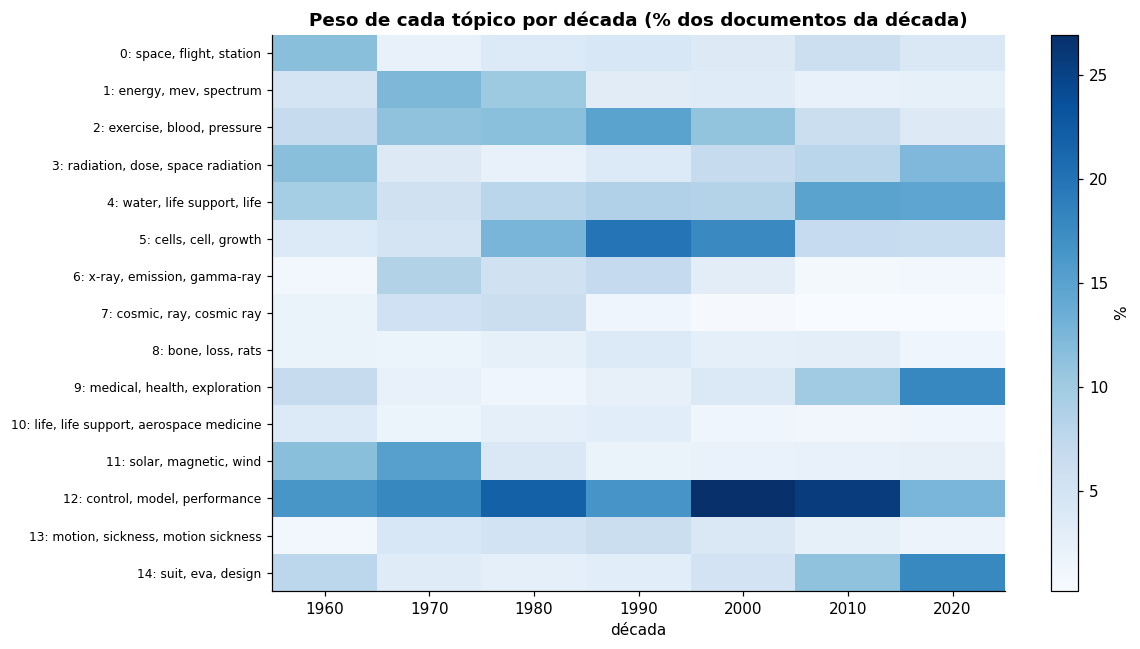

In [ ]:
# peso de cada tópico por década (porcentagem dos documentos da década)
prev = pd.crosstab(corpus["decada"], corpus["topico"], normalize="index") * 100
prev = prev.loc[prev.index >= 1960]
rotulos = [f"{i}: " + ", ".join(termos[np.argsort(nmf.components_[i])[::-1][:3]]) for i in prev.columns]

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(prev.T.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(prev.index)))
ax.set_xticklabels([str(d) for d in prev.index])
ax.set_yticks(range(len(rotulos)))
ax.set_yticklabels(rotulos, fontsize=8)
ax.set_xlabel("década")
ax.set_title("Peso de cada tópico por década (% dos documentos da década)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="%")
plt.tight_layout()
plt.show()

**Leitura**
- Parte relevante do corpus não é saúde humana: há tópicos de astrofísica (raios cósmicos, raios X e gama, vento solar, espectros de energia), vindos da categoria Space Radiation, e de crescimento de plantas, vindos de Life Sciences.
- O maior tópico é de controle, desempenho e software (fatores humanos e interfaces), concentrado em Man/System.
- Os tópicos diretamente úteis ao desafio são exercício e sistema cardiovascular, perda óssea, dose de radiação, enjoo de movimento e saúde da tripulação em missões.
- O tópico de saúde da tripulação em missões cresce nas décadas recentes, enquanto astrofísica perde peso.
- Os números e a ordem dos tópicos podem variar levemente entre versões do scikit-learn. A leitura deve ser feita pelos termos.

## 12. Candidatos a limiares

Busca nos resumos por números acompanhados de unidades associadas aos indicadores (mmHg, bpm, mg/dL, mSv, °C, % por mês). A extração é feita em duas versões:

- **Bruta:** qualquer número seguido da unidade.
- **Contextual:** só conta o valor se um termo do indicador correspondente aparecer perto dele (até 120 caracteres antes ou 60 depois). Exemplo: `mmHg` só vale se houver *blood pressure*, *systolic* ou similar por perto. Isso descarta pressão parcial de CO2, pressão intraocular, temperatura ambiente e doses de experimento em laboratório.

Números com vírgula seguida de três dígitos (`2,049`) são lidos como milhar, já que os textos estão em inglês.

In [ ]:
# unidade: (padrão da unidade, indicador associado, termos que precisam aparecer por perto)
UNIDADES = {
    "mmHg": (r"mm ?hg", "pressão arterial",
             r"blood pressure|systolic|diastolic|arterial pressure|mean arterial|hypertensi|hypotensi|orthostatic"),
    "bpm": (r"bpm|beats ?/ ?min|beats per minute", "frequência cardíaca",
            r"heart rate|\bhr\b|pulse|cardiac|tachycard|bradycard"),
    "mg/dL": (r"mg ?/ ?dl", "glicemia",
              r"glucose|glyc|insulin|diabet"),
    "mSv/Sv": (r"m?sv\b|millisieverts?|sieverts?", "radiação",
               r"astronaut|crew|mission|career|exposure limit|permissible|spaceflight|eva\b|\biss\b"),
    "mGy/Gy": (r"m?gy\b|milligrays?|\bgrays?\b", "radiação",
               r"astronaut|crew|mission|career|exposure limit|permissible|spaceflight|eva\b|\biss\b"),
    "°C": (r"°\s?c\b|deg(?:rees)? ?c\b", "temperatura corporal",
           r"body temperature|core temperature|skin temperature|oral temperature|rectal|thermoregulat|fever|hypertherm|hypotherm"),
    "%/mês": (r"% ?(?:per|/|a) ?month", "osso e músculo",
              r"\bbone|bmd\b|mineral|skeletal|muscle|lean mass|strength"),
    "h/noite": (r"h(?:ours?|rs?)? ?(?:per|/|a) ?night", "sono",
                r"\bsleep|circadian|insomnia"),
}

NUM = r"\d{1,3}(?:,\d{3})+(?:\.\d+)?|\d+(?:\.\d+)?"
NUMERO = rf"(?<![\d.,])({NUM})(?:\s?(?:-|–|to|±)\s?({NUM}))?\s?"
ANTES, DEPOIS = 120, 60

def para_float(s):
    return float(s.replace(",", "")) if s else None

def extrair_valores(texto, contextual=True):
    achados = []
    for unidade, (padrao, indicador, contexto) in UNIDADES.items():
        for m in re.finditer(NUMERO + "(?:" + padrao + ")", texto, flags=re.IGNORECASE):
            janela = texto[max(0, m.start() - ANTES): m.end() + DEPOIS]
            tem_contexto = re.search(contexto, janela, flags=re.IGNORECASE) is not None
            if contextual and not tem_contexto:
                continue
            achados.append({
                "unidade": unidade,
                "indicador": indicador,
                "trecho": m.group(0).strip(),
                "valor": para_float(m.group(1)),
                "valor_fim": para_float(m.group(2)),
                "janela": " ".join(janela.split()),
            })
    return achados

dados["valores_brutos"] = dados["resumo"].apply(lambda t: extrair_valores(t, contextual=False))
dados["valores_resumo"] = dados["resumo"].apply(extrair_valores)
dados["n_valores_resumo"] = dados["valores_resumo"].str.len()

def tabela_valores(coluna):
    v = dados[["id", coluna]].explode(coluna).dropna()
    return pd.concat([v[["id"]].reset_index(drop=True), pd.DataFrame(v[coluna].tolist())], axis=1)

brutos = tabela_valores("valores_brutos")
valores = tabela_valores("valores_resumo")

comparacao = pd.DataFrame({
    "bruta": brutos["unidade"].value_counts(),
    "contextual": valores["unidade"].value_counts(),
}).fillna(0).astype(int).sort_values("bruta", ascending=False)
comparacao["pct_mantido"] = (100 * comparacao["contextual"] / comparacao["bruta"]).round(0)

print("documentos com valor (extração bruta):", (dados["valores_brutos"].str.len() > 0).sum())
print("documentos com valor (extração contextual):", (dados["n_valores_resumo"] > 0).sum())
comparacao

documentos com valor (extração bruta): 848
documentos com valor (extração contextual): 211


,bruta,contextual,pct_mantido
unidade,,,
mmHg,725,155,21.0
mGy/Gy,462,12,3.0
°C,410,20,5.0
bpm,139,110,79.0
mSv/Sv,52,29,56.0
%/mês,19,17,89.0
mg/dL,19,11,58.0
h/noite,6,6,100.0


In [ ]:
# exemplos da extração contextual, com o trecho ao redor do valor
for unidade, grupo in valores.groupby("unidade"):
    print(f"--- {unidade} ({len(grupo)}) ---")
    for janela in grupo["janela"].head(4):
        print("  ...", janela[:170], "...")

--- %/mês (17) ---
  ... Blanc et al. (1996) indicated that there was still a mean rate of loss of bone mineral density in the proximal femur of 1.58% per month (n=18, flight duration 4 - 14.4 mo ...
  ... re assigned for exercise each day. Areal BMD decreased in the femoral neck and total hip by 0.71 +/- 0.34% and 0.81 +/- 0.21% per month, respectively. Changes in muscle v ...
  ... Bone minerals decline in microgravity, and bone mineral density (BMD) losses of approximately -1 to -1.5% per month were calculated for astronauts serving on long-duratio ...
  ... MD] at load-bearing sites of the hip and spine sustain significant loss during space flight, estimated at approximately 0.5-1.0% per month. However, the long-term effects ...
--- bpm (110) ---
  ... uring LBNP at -50 torr compared to control measurements at ambient temperature. Heart rates were lowered significantly (8 beats/min) and systolic arterial blood pressure  ...
  ... d for observing the heart rate (HR), metabolic equiv

In [ ]:
# distribuição dos valores extraídos (primeiro número de cada trecho)
distribuicao = valores.groupby("unidade")["valor"].describe(percentiles=[0.1, 0.5, 0.9])
distribuicao[["count", "min", "10%", "50%", "90%", "max"]].round(2)

,count,min,10%,50%,90%,max
unidade,,,,,,
%/mês,17.0,0.21,0.50,1.20,2.00,2.00
bpm,110.0,0.10,1.00,5.00,103.00,194.00
h/noite,6.0,4.00,4.00,4.10,7.10,8.20
mGy/Gy,12.0,0.00,0.01,1.45,5.70,50.00
mSv/Sv,29.0,0.70,1.00,4.00,600.00,600.00
mg/dL,11.0,0.50,6.00,38.23,854.00,2049.00
mmHg,155.0,0.00,1.10,7.00,66.00,200.00
°C,20.0,0.05,0.10,17.50,35.17,38.28


A distribuição serve como checagem de plausibilidade. Valores muito fora da faixa fisiológica (pressão arterial acima de 250 mmHg, frequência acima de 220 bpm) indicam diferenças, durações ou erros de extração, e devem ser conferidos no texto.

In [ ]:
# ranking dos documentos com valores contextualizados
candidatos = dados[dados["n_valores_resumo"] > 0].copy()
candidatos["indicadores"] = candidatos["valores_resumo"].apply(
    lambda vs: ", ".join(sorted({v["indicador"] for v in vs}))
)
candidatos["trechos"] = candidatos["valores_resumo"].apply(lambda vs: " | ".join(v["trecho"] for v in vs))
candidatos["pontuacao"] = (
    candidatos["n_valores_resumo"].clip(upper=5)
    + 2 * candidatos["tem_texto"]
    + 2 * (candidatos["ano"].fillna(0) >= 2000)
    + candidatos["tipo"].isin(["TECHNICAL_PUBLICATION", "TECHNICAL_MEMORANDUM", "CONTRACTOR_REPORT", "SPECIAL_PUBLICATION"])
)
candidatos = candidatos.sort_values(["pontuacao", "ano"], ascending=False)

print("documentos candidatos:", len(candidatos))
print(candidatos["indicadores"].str.split(", ").explode().value_counts())

COLS_CAND = ["id", "titulo", "ano", "tipo", "indicadores", "trechos", "n_valores_resumo", "tem_texto", "link_texto", "pontuacao"]  # "sujeito" entra após a classificação
candidatos[COLS_CAND].head(20)

documentos candidatos: 211
indicadores
pressão arterial        100
frequência cardíaca      65
radiação                 26
osso e músculo           17
temperatura corporal     15
glicemia                  5
sono                      3
Name: count, dtype: int64


,id,titulo,ano,tipo,indicadores,trechos,n_valores_resumo,tem_texto,link_texto,pontuacao
4634,20150021474,Pilot Field Test: Use of a Compression Garment During a Stand Test After Long-Duration Space Flight,2016,ABSTRACT,"frequência cardíaca, pressão arterial",0.8 mmHg | 15 bpm | 14 bpm | 38 bpm | 7.4 bpm | 25.0 bpm | 16.0 bpm,7,True,https://ntrs.nasa.gov/api/citations/20150021474/downloads/20150021474.txt,9
5796,20040100724,Biological Response to SPE Exposures,2004,OTHER,radiação,2.2 Sv | 1.8 Sv | 1.6 Gy | 1.3 Gy,4,True,https://ntrs.nasa.gov/api/citations/20040100724/downloads/20040100724.txt,8
7243,20000057301,Effect of In-Flight Exercise and Extravehicular Activity on Postflight Stand Tests,2000,TECHNICAL_MEMORANDUM,frequência cardíaca,5 bpm | 1bpm | 2 bpm,3,True,https://ntrs.nasa.gov/api/citations/20000057301/downloads/20000057301.txt,8
1082,20110014835,Compression Stockings May Ameliorate Orthostatic Intolerance in Astronauts After Short-Duration ...,2011,PRESENTATION,"frequência cardíaca, pressão arterial",15 mmHg | 2 mmHg | 4 beats/min,3,True,https://ntrs.nasa.gov/api/citations/20110014835/downloads/20110014835.txt,7
4102,20040088399,Baroreflex buffering and susceptibility to vasoactive drugs,2002,REPRINT,pressão arterial,1.6 mm Hg | 1.1 mm Hg | 3.9 mm Hg | 3.4 mm Hg | 3.4 mm Hg,5,False,None,7
7378,20040088407,Water drinking as a treatment for orthostatic syndromes,2002,REPRINT,"frequência cardíaca, pressão arterial",3.4 mm Hg | 13 mm Hg | 5 mm Hg | 23 beats per minute | 21 beats per minute,5,False,None,7
24675,20040088508,Selective norepinephrine reuptake inhibition as a human model of orthostatic intolerance,2002,REPRINT,"frequência cardíaca, pressão arterial",2 mm Hg | 2 mm Hg | 3 mm Hg | 2 bpm | 3 bpm | 4 bpm,6,False,None,7
22180,19950012725,"Drink composition and cycle-ergometer endurance in men: Carbohydrate, Na(+), osmolality",1994,TECHNICAL_MEMORANDUM,glicemia,"416 mg/dL | 2,049 mg/dL | 854 mg/dL | 0.5 mg/dL",4,True,https://ntrs.nasa.gov/api/citations/19950012725/downloads/19950012725.txt,7
27868,20150023508,Plasma Glucose Levels for Red Drum Sciaenops Ocellatus in a Florida Estuarine Fisheries Reserve,2015,PREPRINT,glicemia,38.23 mg / dL | 17 - 69 mg / dL,2,True,https://ntrs.nasa.gov/api/citations/20150023508/downloads/20150023508.txt,6
26574,20110020797,Expression of Enzymes that Metabolize Medications,2011,ABSTRACT,radiação,50 mGy | 6Gy,2,True,https://ntrs.nasa.gov/api/citations/20110020797/downloads/20110020797.txt,6


### Sujeito da medida

O filtro de contexto não verifica se o valor é de humanos. Esta etapa classifica cada candidato pelo sujeito do estudo, a partir de termos no título e no resumo:

- **humano:** astronaut, crew, subjects, volunteers, men, women, bed rest e similares;
- **animal:** rats, mice, monkeys, fish e similares;
- **células:** cell culture, in vitro, cell line e similares;
- **misto:** termos de mais de um grupo;
- **indefinido:** nenhum termo encontrado.

In [ ]:
SUJEITOS = {
    "humano": r"astronaut|cosmonaut|\bcrew|\bhuman|\bsubjects?\b|volunteer|\bmen\b|\bwomen\b|\bpatients?\b|participants?|bed rest|\bpilots?\b",
    "animal": r"\brats?\b|\bmice\b|\bmouse\b|rodent|monkey|primate|\bfish|\bdogs?\b|rabbit|\bpigs?\b|animal",
    "células": r"cell culture|in vitro|cell line|cultured cells|tissue culture",
}

def classificar_sujeito(texto):
    achados = [nome for nome, padrao in SUJEITOS.items() if re.search(padrao, texto, flags=re.IGNORECASE)]
    if not achados:
        return "indefinido"
    return achados[0] if len(achados) == 1 else "misto"

candidatos["sujeito"] = (candidatos["titulo"].fillna("") + " " + candidatos["resumo"]).apply(classificar_sujeito)

print(candidatos["sujeito"].value_counts().to_frame("documentos").assign(
    pct=lambda t: (100 * t["documentos"] / t["documentos"].sum()).round(0)))

por_sujeito = (candidatos.assign(indicador=candidatos["indicadores"].str.split(", ")).explode("indicador")
               .reset_index(drop=True)
               .pipe(lambda t: pd.crosstab(t["indicador"], t["sujeito"], margins=True, margins_name="total")))
por_sujeito

            documentos   pct
sujeito                     
humano             164  78.0
animal              26  12.0
misto               15   7.0
indefinido           4   2.0
células              2   1.0


sujeito,animal,células,humano,indefinido,misto,total
indicador,,,,,,
frequência cardíaca,8,0,56,1,0,65
glicemia,2,1,2,0,0,5
osso e músculo,0,1,14,0,2,17
pressão arterial,14,0,79,2,5,100
radiação,0,0,19,1,6,26
sono,0,0,3,0,0,3
temperatura corporal,4,0,9,0,2,15
total,28,2,182,4,15,231


In [ ]:
# exemplos por sujeito, para conferir a classificação
for sujeito, grupo in candidatos.groupby("sujeito"):
    print(f"--- {sujeito} ---")
    for t in grupo["titulo"].head(4):
        print("  ", t[:110])

--- animal ---
   Plasma Glucose Levels for Red Drum Sciaenops Ocellatus in a Florida Estuarine Fisheries Reserve
   Effect of Blockade of Nitric Oxide Synthesis on the Renin Secretory Response to Frusemide in Conscious Rabbits
   Ventricular filling slows epicardial conduction and increases action potential duration in an optical mapping 
   Peripheral vascular responses to heat stress after hindlimb suspension
--- células ---
   Biophotonics and Bone Biology
   Non-invasive optical detection of glucose in cell culture nutrient medium
--- humano ---
   Pilot Field Test: Use of a Compression Garment During a Stand Test After Long-Duration Space Flight
   Effect of In-Flight Exercise and Extravehicular Activity on Postflight Stand Tests
   Compression Stockings May Ameliorate Orthostatic Intolerance in Astronauts After Short-Duration Space Flight
   Baroreflex buffering and susceptibility to vasoactive drugs
--- indefinido ---
   Relationship between systolic and diastolic function with

**Leitura do sujeito**
- 78% dos candidatos (164) são estudos em humanos, 12% (26) em animais, 1% em células, 7% mistos e 2% sem sujeito identificado.
- Os falsos positivos de sujeito se concentram em pressão arterial (14 de 100 com sujeito animal) e frequência cardíaca (8 de 65).
- Glicemia tem só 5 candidatos, e 2 são em humanos. A base do NTRS para esse indicador é praticamente inexistente.
- A classificação é por termos e pode errar: "human" aparece em textos sobre modelos animais, e os casos mistos precisam de leitura.

**Leitura**
- O filtro de contexto descarta a maior parte das ocorrências de mmHg, °C e Gy, que eram pressão de gases e de olhos, temperatura de experimento e doses de laboratório. Taxas por mês e horas de sono quase não mudam, porque essas unidades já vinham no contexto certo.
- Pressão arterial e frequência cardíaca continuam liderando, agora com valores de fato cardiovasculares.
- Sono e humor seguem quase ausentes: valores comportamentais vêm em escalas e questionários, não em unidades físicas.

**Limitações**
- A janela de contexto reduz, mas não elimina, falsos positivos. Um valor pode estar perto do termo certo e ainda ser uma diferença ("aumento de 8 bpm") em vez de uma faixa.
- Os valores são extraídos só dos resumos. A lista é um ponto de partida para leitura, não um conjunto de limiares validado.
- Os valores extraídos não substituem limites oficiais. Fora desta base, a norma NASA-STD-3001 reúne limites de saúde e exposição da tripulação e pode servir de referência a verificar.

In [ ]:
candidatos[COLS_CAND + ["sujeito"]].to_csv(os.path.join(SAIDA_DIR, "candidatos_limiares.csv"), index=False)
valores.drop(columns="janela").to_csv(os.path.join(SAIDA_DIR, "valores_extraidos.csv"), index=False)
print("salvos em", SAIDA_DIR, ": candidatos_limiares.csv, valores_extraidos.csv")

salvos em /content/drive/MyDrive/space-apps-2026/ntrs/eda : candidatos_limiares.csv, valores_extraidos.csv


### Texto completo dos candidatos

Os resumos trazem poucos valores. Esta etapa aplica a mesma extração contextual ao texto completo (`.txt` já extraído pelo NTRS) dos candidatos que têm texto disponível, para medir quanto ele acrescenta.

Os textos ficam salvos em `textos_candidatos.json.gz` no Drive. Se o arquivo já existir, é carregado em vez de baixado de novo. O download leva de 5 a 10 minutos e só depende de internet, sem chave de API.

In [ ]:
import gzip

TEXTOS_PATH = os.path.join(SAIDA_DIR, "textos_candidatos.json.gz")
com_texto = candidatos[candidatos["tem_texto"]]

if os.path.exists(TEXTOS_PATH):
    with gzip.open(TEXTOS_PATH, "rt", encoding="utf-8") as f:
        textos = json.load(f)
    print(f"{len(textos)} textos carregados do Drive")
else:
    textos = {}
    for i, (doc_id, link) in enumerate(zip(com_texto["id"], com_texto["link_texto"])):
        try:
            resp = requests.get(link, timeout=60)
            resp.raise_for_status()
            textos[str(doc_id)] = resp.text
        except requests.RequestException as e:
            print(f"falha em {doc_id}: {e}")
        if (i + 1) % 50 == 0:
            print(f"{i + 1} de {len(com_texto)}")
        time.sleep(0.3)
    with gzip.open(TEXTOS_PATH, "wt", encoding="utf-8") as f:
        json.dump(textos, f)
    print(f"{len(textos)} textos baixados e salvos em {TEXTOS_PATH}")

237 textos carregados do Drive


In [ ]:
# todos os documentos com texto salvo, inclusive de versões anteriores da lista de candidatos
analisados = dados[dados["id"].astype(str).isin(textos.keys())]

linhas = []
valores_texto = []
for _, c in analisados.iterrows():
    texto = textos.get(str(c["id"]))
    if texto is None:
        continue
    achados = extrair_valores(texto)
    for a in achados:
        valores_texto.append({"id": c["id"], **a})
    linhas.append({
        "id": c["id"],
        "titulo": c["titulo"][:70],
        "tipo": c["tipo"],
        "palavras_texto": len(texto.split()),
        "valores_resumo": c["n_valores_resumo"],
        "valores_texto": len(achados),
        "indicadores_texto": ", ".join(sorted({a["indicador"] for a in achados})),
    })

comp_texto = pd.DataFrame(linhas)
valores_texto = pd.DataFrame(valores_texto)

print("documentos analisados:", len(comp_texto))
print("valores no resumo:", comp_texto["valores_resumo"].sum(), "| no texto completo:", comp_texto["valores_texto"].sum())
print("mediana por documento, resumo:", comp_texto["valores_resumo"].median(), "| texto completo:", comp_texto["valores_texto"].median())
print("documentos com mais valores no texto que no resumo:", (comp_texto["valores_texto"] > comp_texto["valores_resumo"]).sum())
comp_texto.sort_values("valores_texto", ascending=False).head(15)

documentos analisados: 237
valores no resumo: 84 | no texto completo: 297
mediana por documento, resumo: 0.0 | texto completo: 0.0
documentos com mais valores no texto que no resumo: 44


,id,titulo,tipo,palavras_texto,valores_resumo,valores_texto,indicadores_texto
166,20250006168,Moon 2 Mars Space Radiation Protection “Buying Down” Risks to Crew,CONFERENCE_PAPER,5928,1,39,radiação
83,20260002939,Evidence Report: Risk of Ionizing Radiation Carcinogenesis,CONTRIBUTION_TO_LARGER_WORK,36121,1,24,radiação
18,20150016006,Evidence Report: Risk of Cardiovascular Disease and Other Degenerative,OTHER,18944,0,19,radiação
177,19950005397,Effects of oral glucose on exercise thermoregulation in men after wate,TECHNICAL_MEMORANDUM,21613,0,18,"frequência cardíaca, glicemia, pressão arterial, temperatura corporal"
117,19800024574,A microprocessor-based cardiotachometer,CONTRACTOR_REPORT,7279,1,11,frequência cardíaca
122,20000057301,Effect of In-Flight Exercise and Extravehicular Activity on Postflight,TECHNICAL_MEMORANDUM,9101,3,11,frequência cardíaca
174,19950012725,"Drink composition and cycle-ergometer endurance in men: Carbohydrate,",TECHNICAL_MEMORANDUM,4081,4,10,"frequência cardíaca, glicemia, temperatura corporal"
193,20150023508,Plasma Glucose Levels for Red Drum Sciaenops Ocellatus in a Florida Es,PREPRINT,3006,2,10,glicemia
72,20150021474,Pilot Field Test: Use of a Compression Garment During a Stand Test Aft,ABSTRACT,707,7,7,"frequência cardíaca, pressão arterial"
75,20160004369,Evidence Report: Risk of Radiation Carcinogenesis,OTHER,28782,0,6,radiação


In [ ]:
por_ind = pd.DataFrame({
    "resumo": valores[valores["id"].isin(comp_texto["id"])]["indicador"].value_counts(),
    "texto_completo": valores_texto["indicador"].value_counts(),
}).fillna(0).astype(int).sort_values("texto_completo", ascending=False)
por_ind

,resumo,texto_completo
indicador,,
radiação,16,122
frequência cardíaca,29,62
pressão arterial,15,47
glicemia,8,29
osso e músculo,13,19
temperatura corporal,3,18


In [ ]:
# distribuição dos valores encontrados no texto completo
dist_texto = valores_texto.groupby("unidade")["valor"].describe(percentiles=[0.1, 0.5, 0.9])
dist_texto[["count", "min", "10%", "50%", "90%", "max"]].round(2)

,count,min,10%,50%,90%,max
unidade,,,,,,
%/mês,19.0,0.05,0.50,1.00,2.00,3.0
bpm,62.0,0.00,2.10,16.00,174.50,300.0
mGy/Gy,36.0,0.00,0.22,7.52,1750.00,6000.0
mSv/Sv,86.0,0.00,1.00,100.00,665.00,2000.0
mg/dL,29.0,0.50,1.60,35.70,854.00,2049.0
mmHg,47.0,0.80,1.80,20.00,58.00,220.0
°C,18.0,0.10,0.11,0.64,33.87,38.5


In [ ]:
valores_texto.drop(columns="janela").to_csv(os.path.join(SAIDA_DIR, "valores_texto_completo.csv"), index=False)
print("salvo valores_texto_completo.csv")

salvo valores_texto_completo.csv


**Leitura**
- Nos 237 documentos com texto salvo, o texto completo rende cerca de 3,5 vezes mais valores contextualizados que os resumos (de 84 para 297), mas o ganho se concentra em poucos documentos: só 44 têm mais valores no texto que no resumo, e a mediana por documento continua em zero.
- Os documentos mais ricos são os **Evidence Reports** do Human Research Program (ex.: *Risk of Ionizing Radiation Carcinogenesis*, *Risk of Cardiovascular Disease*). São revisões oficiais da NASA sobre cada risco à saúde, com valores e referências consolidados. São a melhor porta de entrada do NTRS para o projeto.
- Radiação é o indicador que mais ganha com o texto completo (de 16 para 122 valores), porque limites e doses de missão aparecem no corpo dos relatórios, não nos resumos.
- Persistem falsos positivos de domínio: glicemia de peixes (*Red Drum*) e de meio de cultura celular passam no filtro de contexto. A leitura humana dos candidatos continua necessária.

## 13. Conclusões

### Achados

**Cobertura**
- 41.866 documentos únicos nas categorias de saúde, de 1958 a 2026, com mediana de publicação em 1994.
- Cerca de 75% não mencionam nenhum indicador do desafio. Parte do recorte é astrofísica (Space Radiation), botânica e biologia celular (Life Sciences) e engenharia de sistemas (Man/System).
- O núcleo com algum indicador, publicado desde 2000 e com texto completo, tem 2.629 documentos.
- Radiação, osso, músculo e pressão arterial têm cobertura ampla. Temperatura corporal e glicemia têm menos de 50 documentos recentes com texto completo cada.

**Qualidade**
- Resumo em 96% dos documentos. Texto completo em 54%, acima de 90% desde 2010. REPRINT, o tipo mais comum, quase nunca tem texto.
- Problemas da fonte: capitalização inconsistente de categorias (afeta até o filtro da API), nomes de autores não padronizados, um ano inválido, códigos de centro que não são centros (`CDMS` com 53% dos registros, `2230`), palavras-chave em só 24% dos registros, cerca de 5.700 resumos com menos de 20 palavras.
- A API limita a paginação a 10.000 registros por consulta. O fatiamento por data deixou de fora 3% dos documentos (os sem data).

**Valores numéricos**
- Só 2% dos resumos trazem números com unidades dos indicadores. Com filtro de contexto, restam 211 documentos, concentrados em pressão arterial e frequência cardíaca.
- 78% desses candidatos são estudos em humanos e 12% em animais.
- O texto completo multiplica os valores encontrados, sobretudo de radiação. Os documentos mais ricos são os Evidence Reports do Human Research Program.
- Sono e humor quase não aparecem com valores, porque se medem por escalas e questionários.

### Implicações possíveis

Opções para a decisão do grupo, não recomendações fechadas.

- O NTRS não traz medições individuais de astronautas. Sinais vitais, se a solução precisar, terão de ser simulados ou vir de outra fonte.
- A cobertura por indicador pode apoiar a escolha de quais indicadores monitorar.
- Os Evidence Reports do HRP são o ponto de partida mais rico para faixas e limiares encontrado na base. A norma NASA-STD-3001, externa a esta análise, é outra fonte a verificar.
- Se a solução citar documentos, o corpus precisaria de filtro por sujeito e remoção dos temas fora do escopo.
- Sono e humor dependem de outras fontes, como o OSDR e o Life Sciences Data Archive.

### Arquivos gerados em `eda/`
- `candidatos_limiares.csv`: documentos com valores contextualizados, trechos, sujeito e pontuação.
- `valores_extraidos.csv`: um valor por linha, extraído dos resumos.
- `valores_texto_completo.csv`: um valor por linha, extraído do texto completo.
- `textos_candidatos.json.gz`: textos completos baixados.